In [1]:
import os
import sys
import tempfile
import time
from pathlib import Path

import duckdb
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

TRIMESTRE = "2019Q1"
VENTANA_P1 = 12
VENTANA_P2 = 3
PANDEMIA = (202003, 202112)

RAIZ = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(RAIZ / "src"))
from riesgo_credito.procesamiento import esquema

DIR_DATOS = RAIZ / "data" / "crudos" / TRIMESTRE
ARCHIVO_ORIG = DIR_DATOS / f"orig_{TRIMESTRE}.txt"
ARCHIVO_PERF = DIR_DATOS / f"perf_{TRIMESTRE}.txt"
DIR_FIGURAS = RAIZ / "docs" / "reportes" / "figuras" / "eda"
DIR_FIGURAS.mkdir(parents=True, exist_ok=True)

pd.set_option("display.width", 200)
pd.set_option("display.max_columns", 30)

con = duckdb.connect()
try:
    con.execute("PRAGMA disable_progress_bar")
except duckdb.Error:
    pass
con.execute(f"SET temp_directory = '{(Path(tempfile.gettempdir()) / 'eda_duckdb').as_posix()}'")
try:
    ram_gb = os.sysconf("SC_PAGE_SIZE") * os.sysconf("SC_PHYS_PAGES") / 1e9
    con.execute(f"SET memory_limit = '{max(1, int(ram_gb * 0.5))}GB'")
except (ValueError, AttributeError, OSError):
    pass


def consulta(sql):
    df = con.execute(sql).df()
    for c in df.columns:
        if pd.api.types.is_extension_array_dtype(df[c]) and pd.api.types.is_numeric_dtype(df[c]):
            df[c] = df[c].astype("float64") if df[c].isna().any() else df[c].astype(df[c].dtype.numpy_dtype)
    return df


def a_fecha(aaaamm):
    s = pd.Series(aaaamm).astype(int)
    return pd.to_datetime(dict(year=s // 100, month=s % 100, day=1))


def guardar(fig, nombre):
    fig.savefig(DIR_FIGURAS / f"{nombre}.png", dpi=150, bbox_inches="tight")

In [2]:
formato_orig, _ = esquema.detectar_formato(ARCHIVO_ORIG, "originacion")
formato_perf, _ = esquema.detectar_formato(ARCHIVO_PERF, "desempeno")

COLUMNAS_PERF = ["loan_id", "period", "current_upb", "dlq_status", "loan_age", "zero_balance_code",
                 "eltv", "mod_flag", "dlq_disaster", "assistance_plan"]

t0 = time.time()
con.execute("CREATE OR REPLACE TABLE orig AS " + esquema.consulta_lectura(ARCHIVO_ORIG, "originacion"))
# La edad se calcula desde el primer pago porque loan_age se reinicia cuando el crédito se modifica
con.execute(f"""
    CREATE OR REPLACE TABLE perf AS
    SELECT p.*,
           (p.period // 100) * 12 + p.period % 100 AS mes,
           (p.period // 100) * 12 + p.period % 100
             - ((o.first_payment_date // 100) * 12 + o.first_payment_date % 100) + 1 AS edad,
           TRY_CAST(p.dlq_status AS INTEGER) AS dlq_num,
           TRY_CAST(p.zero_balance_code AS INTEGER) AS zb
    FROM ({esquema.consulta_lectura(ARCHIVO_PERF, "desempeno", COLUMNAS_PERF)}) p
    LEFT JOIN orig o USING (loan_id)
""")
rango = consulta("SELECT MIN(period) AS desde, MAX(period) AS hasta, MAX(edad) AS edad_maxima FROM perf").iloc[0]
PERIODO_FIN = int(rango.hasta)
n_creditos = int(consulta("SELECT COUNT(*) FROM orig").iloc[0, 0])
n_registros = int(consulta("SELECT COUNT(*) FROM perf").iloc[0, 0])

print(f"Formato: originación {formato_orig}, desempeño {formato_perf} · lectura en {time.time() - t0:.0f} s")
print(f"Créditos: {n_creditos:,} · registros mensuales: {n_registros:,}")
print(f"Desempeño de {int(rango.desde)} a {PERIODO_FIN} · edad máxima: {int(rango.edad_maxima)} meses")
consulta("""
    SELECT first_payment_date AS mes_primer_pago, COUNT(*) AS creditos,
           ROUND(100.0 * COUNT(*) / SUM(COUNT(*)) OVER (), 2) AS pct
    FROM orig GROUP BY 1 ORDER BY 2 DESC LIMIT 5
""")

Formato: originación nuevo, desempeño nuevo · lectura en 14 s
Créditos: 279,861 · registros mensuales: 9,821,276
Desempeño de 201901 a 202603 · edad máxima: 86 meses


,mes_primer_pago,creditos,pct
0,201905,104772,37.44
1,201904,94315,33.70
2,201903,77872,27.83
3,201906,1538,0.55
4,201902,753,0.27


## Calidad de los datos

In [3]:
def perfil_columnas(ruta, tipo):
    _, columnas = esquema.detectar_formato(ruta, tipo)
    partes = []
    for c in columnas:
        codigos = esquema.NO_DISPONIBLE.get(c, [])
        cond_nd = f"trim({c}) IN ({', '.join(repr(x) for x in codigos)})" if codigos else "FALSE"
        partes.append(f"COUNT(*) FILTER (WHERE {c} IS NULL OR trim({c}) = '') AS \"{c}|vacios\", "
                      f"COUNT(*) FILTER (WHERE {cond_nd}) AS \"{c}|no_disp\", "
                      f"approx_count_distinct(nullif(trim({c}), '')) AS \"{c}|distintos\"")
    fila = con.execute(f"SELECT COUNT(*) AS n, {', '.join(partes)} FROM ({esquema.consulta_cruda(ruta, tipo)})").df().iloc[0]
    n = fila["n"]
    tabla = pd.DataFrame([{"columna": c,
                           "pct_vacios": 100 * fila[f"{c}|vacios"] / n,
                           "pct_no_disponible": 100 * fila[f"{c}|no_disp"] / n,
                           "distintos": int(fila[f"{c}|distintos"])} for c in columnas])
    # Sin información: todo vacío, o un único valor sin vacíos
    tabla["sin_informacion"] = (tabla.pct_vacios == 100) | ((tabla.distintos <= 1) & (tabla.pct_vacios == 0))
    return tabla


perfil = pd.concat([perfil_columnas(ARCHIVO_ORIG, "originacion").assign(archivo="originación"),
                    perfil_columnas(ARCHIVO_PERF, "desempeno").assign(archivo="desempeño")])
SIN_INFORMACION = perfil.loc[perfil.sin_informacion, "columna"].tolist()
print("Columnas vacías o constantes:", ", ".join(SIN_INFORMACION) if SIN_INFORMACION else "ninguna")
perfil.loc[perfil.pct_no_disponible > 0, ["archivo", "columna", "pct_no_disponible"]] \
    .sort_values("pct_no_disponible", ascending=False).round(3)

Columnas vacías o constantes: ppm_flag, amort_type, io_flag, vantage_score


,archivo,columna,pct_no_disponible
30,originación,vantage_score,100.000
28,originación,valuation_method,94.301
32,desempeño,mi_cancel,67.176
25,desempeño,eltv,12.400
9,originación,dti,0.399
0,originación,credit_score,0.057
8,originación,ocltv,0.003


In [4]:
chequeos = consulta("""
    WITH x AS (
        SELECT loan_id, mes, loan_age, edad, zb, mod_flag,
               mes - LAG(mes) OVER w AS salto_mes,
               loan_age - LAG(loan_age) OVER w AS salto_edad
        FROM perf WINDOW w AS (PARTITION BY loan_id ORDER BY mes)
    ),
    salida AS (SELECT loan_id, MIN(mes) AS mes_salida FROM perf WHERE zb IS NOT NULL GROUP BY 1)
    SELECT
        (SELECT COUNT(*) - COUNT(DISTINCT loan_id) FROM orig) AS duplicados_originacion,
        (SELECT COUNT(*) FROM (SELECT loan_id, period FROM perf GROUP BY 1, 2 HAVING COUNT(*) > 1)) AS duplicados_credito_mes,
        (SELECT COUNT(*) FROM orig o WHERE NOT EXISTS (SELECT 1 FROM perf p WHERE p.loan_id = o.loan_id)) AS creditos_sin_desempeno,
        (SELECT COUNT(*) FROM perf p JOIN salida s USING (loan_id) WHERE p.mes > s.mes_salida) AS registros_despues_de_salir,
        COUNT(*) FILTER (WHERE salto_mes > 1) AS huecos_de_meses,
        COUNT(*) FILTER (WHERE salto_edad < 0) AS loan_age_retrocede,
        COUNT(*) FILTER (WHERE salto_edad < 0 AND mod_flag = 'Y') AS loan_age_retrocede_al_modificarse,
        ROUND(100 * AVG((loan_age = edad)::INTEGER) FILTER (WHERE zb IS NULL), 2) AS pct_loan_age_igual_a_edad
    FROM x
""")
chequeos.T.rename(columns={0: "valor"})

,valor
duplicados_originacion,0.00
duplicados_credito_mes,0.00
creditos_sin_desempeno,0.00
registros_despues_de_salir,0.00
huecos_de_meses,5.00
loan_age_retrocede,2969.00
loan_age_retrocede_al_modificarse,2966.00
pct_loan_age_igual_a_edad,99.04


In [5]:
consulta("""
    SELECT 'puntaje de crédito' AS variable, MIN(credit_score) AS minimo, MAX(credit_score) AS maximo, COUNT(*) FILTER (WHERE credit_score IS NULL) AS nulos FROM orig
    UNION ALL SELECT 'deuda-ingreso (%)', MIN(dti), MAX(dti), COUNT(*) FILTER (WHERE dti IS NULL) FROM orig
    UNION ALL SELECT 'préstamo-valor (%)', MIN(oltv), MAX(oltv), COUNT(*) FILTER (WHERE oltv IS NULL) FROM orig
    UNION ALL SELECT 'préstamo-valor combinada (%)', MIN(ocltv), MAX(ocltv), COUNT(*) FILTER (WHERE ocltv IS NULL) FROM orig
    UNION ALL SELECT 'tasa de interés (%)', MIN(orig_rate), MAX(orig_rate), COUNT(*) FILTER (WHERE orig_rate IS NULL) FROM orig
    UNION ALL SELECT 'plazo (meses)', MIN(orig_term), MAX(orig_term), COUNT(*) FILTER (WHERE orig_term IS NULL) FROM orig
""")

,variable,minimo,maximo,nulos
0,puntaje de crédito,487.0,837.0,160
1,deuda-ingreso (%),1.0,51.0,1116
2,préstamo-valor (%),4.0,194.0,0
3,préstamo-valor combinada (%),4.0,233.0,7
4,tasa de interés (%),2.5,7.0,0
5,plazo (meses),96.0,548.0,0


Los archivos son consistentes: la llave es única, todos los créditos tienen desempeño y no hay registros después de la salida. Los huecos de meses son pocos frente al total de registros y no justifican una corrección. loan_age retrocede casi siempre en el mes de una modificación, lo que confirma que la edad debe calcularse desde el primer pago. Las columnas sin información se descartan, los códigos de no disponible se tratan como nulos y los valores extremos de préstamo-valor y plazo quedan para revisión en la canalización.

## Perfil de los créditos al originarse

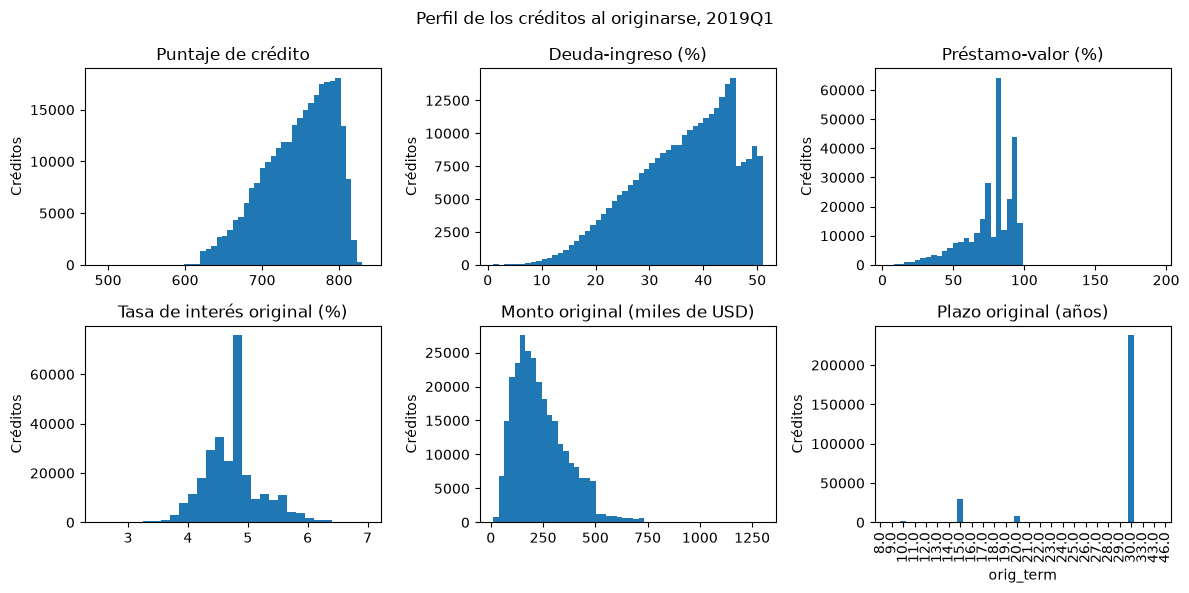

,count,mean,std,min,5%,50%,95%,max
credit_score,279701.0,746.37,45.49,487.0,661.0,754.00,807.00,837.0
dti,278745.0,35.87,9.31,1.0,19.0,37.00,49.00,51.0
oltv,279861.0,75.87,17.33,4.0,40.0,80.00,97.00,194.0
orig_rate,279861.0,4.73,0.47,2.5,4.0,4.75,5.62,7.0
orig_upb,279861.0,238053.42,127214.55,11000.0,75000.0,212000.00,475000.00,1300000.0
orig_term,279861.0,335.15,60.81,96.0,180.0,360.00,360.00,548.0


In [6]:
o = consulta("SELECT * FROM orig")

fig, axs = plt.subplots(2, 3, figsize=(12, 6))
o.credit_score.dropna().plot.hist(bins=50, ax=axs[0, 0], title="Puntaje de crédito")
o.dti.dropna().plot.hist(bins=50, ax=axs[0, 1], title="Deuda-ingreso (%)")
o.oltv.plot.hist(bins=50, ax=axs[0, 2], title="Préstamo-valor (%)")
o.orig_rate.plot.hist(bins=30, ax=axs[1, 0], title="Tasa de interés original (%)")
(o.orig_upb / 1000).plot.hist(bins=50, ax=axs[1, 1], title="Monto original (miles de USD)")
(o.orig_term / 12).round().value_counts().sort_index().plot.bar(ax=axs[1, 2], title="Plazo original (años)")
for ax in axs.flat:
    ax.set_ylabel("Créditos")
fig.suptitle(f"Perfil de los créditos al originarse, {TRIMESTRE}")
fig.tight_layout()
guardar(fig, "perfil_solicitud")
plt.show()

o[["credit_score", "dti", "oltv", "orig_rate", "orig_upb", "orig_term"]].describe(percentiles=[0.05, 0.5, 0.95]).T.round(2)

In [7]:
MAPAS = {
    "purpose": {"P": "Compra", "C": "Refinanciación con retiro", "N": "Refinanciación sin retiro"},
    "occupancy": {"P": "Residencia principal", "I": "Inversión", "S": "Segunda vivienda"},
    "channel": {"R": "Minorista", "C": "Corresponsal", "B": "Corredor"},
    "first_time_homebuyer": {"Y": "Sí", "N": "No"},
}
o["plazo_anios"] = (o.orig_term / 12).round().astype(int)
filas = []
for col in ["purpose", "occupancy", "channel", "first_time_homebuyer", "num_borrowers", "plazo_anios"]:
    pct = o[col].value_counts(normalize=True)
    for valor, p in pct[pct >= 0.01].items():
        filas.append({"variable": col, "valor": MAPAS.get(col, {}).get(valor, valor), "pct": round(100 * p, 1)})
pd.DataFrame(filas)

,variable,valor,pct
0,purpose,Compra,63.3
1,purpose,Refinanciación con retiro,22.6
2,purpose,Refinanciación sin retiro,14.1
3,occupancy,Residencia principal,87.4
4,occupancy,Inversión,8.3
5,occupancy,Segunda vivienda,4.3
6,channel,Minorista,54.3
7,channel,Corresponsal,33.5
8,channel,Corredor,12.2
9,first_time_homebuyer,No,73.4


Es una cartera de buen perfil crediticio, concentrada en compras de residencia principal a 30 años. La relación préstamo-valor se agrupa en unos pocos valores redondos y las tasas están en un rango estrecho.

## Evolución de la cartera

In [8]:
MOTIVOS = {1: "Prepago o vencimiento", 2: "Venta a tercero en remate", 3: "Venta corta o castigo",
           9: "Venta del inmueble adjudicado", 15: "Venta del préstamo completo",
           16: "Titularización de préstamo reperforming", 96: "Defecto de suscripción o administración"}
salidas = consulta("SELECT zb AS codigo, COUNT(DISTINCT loan_id) AS creditos FROM perf WHERE zb IS NOT NULL GROUP BY 1 ORDER BY 2 DESC")
salidas["motivo"] = salidas.codigo.map(MOTIVOS)
salidas["pct"] = (100 * salidas.creditos / n_creditos).round(3)
activos_final = n_creditos - salidas.creditos.sum()
eventos_credito = salidas.loc[salidas.codigo.isin(esquema.CODIGOS_CIERRE_INCUMPLIMIENTO), "creditos"].sum()
print(f"Activos al cierre de {PERIODO_FIN}: {activos_final:,} ({100 * activos_final / n_creditos:.1f} %)")
print(f"Salidas por evento de crédito (02, 03, 09): {eventos_credito:,} ({100 * eventos_credito / n_creditos:.2f} %)")
salidas[["codigo", "motivo", "creditos", "pct"]]

Activos al cierre de 202603: 55,339 (19.8 %)
Salidas por evento de crédito (02, 03, 09): 277 (0.10 %)


,codigo,motivo,creditos,pct
0,1,Prepago o vencimiento,223125,79.727
1,96,Defecto de suscripción o administración,801,0.286
2,16,Titularización de préstamo reperforming,241,0.086
3,2,Venta a tercero en remate,135,0.048
4,9,Venta del inmueble adjudicado,130,0.046
5,15,Venta del préstamo completo,78,0.028
6,3,Venta corta o castigo,12,0.004


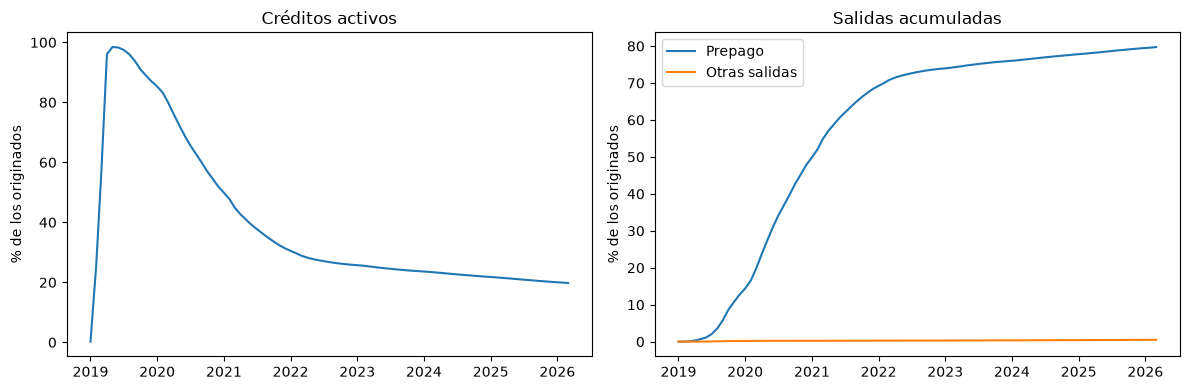

,period,pct_activos,pct_prepago_acum
0,201901,0.2,0.0
12,202001,85.3,14.4
24,202101,49.9,49.9
36,202201,30.5,69.2
48,202301,25.7,74.0
60,202401,23.6,76.0
72,202501,21.8,77.8
84,202601,20.0,79.5


In [9]:
cartera = consulta("""
    SELECT period,
           COUNT(*) FILTER (WHERE zb IS NULL) AS activos,
           COUNT(*) FILTER (WHERE zb = 1) AS prepagos,
           COUNT(*) FILTER (WHERE zb IS NOT NULL AND zb <> 1) AS otras_salidas
    FROM perf GROUP BY 1 ORDER BY 1
""")
cartera["fecha"] = a_fecha(cartera.period)
cartera["pct_activos"] = 100 * cartera.activos / n_creditos
cartera["pct_prepago_acum"] = 100 * cartera.prepagos.cumsum() / n_creditos
cartera["pct_otras_acum"] = 100 * cartera.otras_salidas.cumsum() / n_creditos

fig, axs = plt.subplots(1, 2, figsize=(12, 4))
axs[0].plot(cartera.fecha, cartera.pct_activos)
axs[0].set(title="Créditos activos", ylabel="% de los originados")
axs[1].plot(cartera.fecha, cartera.pct_prepago_acum, label="Prepago")
axs[1].plot(cartera.fecha, cartera.pct_otras_acum, label="Otras salidas")
axs[1].set(title="Salidas acumuladas", ylabel="% de los originados")
axs[1].legend()
fig.tight_layout()
guardar(fig, "evolucion_cartera")
plt.show()

cartera.loc[cartera.period % 100 == 1, ["period", "pct_activos", "pct_prepago_acum"]].round(1)

El prepago domina la vida de esta cosecha: se acelera durante 2020 y 2021 y después avanza lento. Las salidas por un evento de crédito son menos que las salidas por defecto de suscripción, que se excluyen de las etiquetas porque no son un evento de crédito.

## Variables objetivo

- Evento de incumplimiento: un mes con 90 días o más de atraso o adjudicación del inmueble, o una salida con código 02, 03 o 09. Los créditos con código 96 se excluyen.
- Pregunta 1: el crédito es positivo si su primer incumplimiento ocurre en los primeros 12 meses desde el primer pago. Una fila por crédito.
- Pregunta 2: desde un mes en que el crédito está al día, es positivo si incumple en alguno de los 3 meses siguientes. Una fila por crédito y mes.

In [10]:
def crear_resumen(tabla_perf, destino):
    con.execute(f"""
        CREATE OR REPLACE TABLE {destino} AS
        SELECT loan_id,
               MAX(mes) AS mes_ultimo,
               MAX(edad) AS edad_maxima,
               MIN(edad) FILTER (WHERE incumple) AS edad_primer_incumplimiento,
               MIN(mes) FILTER (WHERE incumple) AS mes_primer_incumplimiento,
               MAX(zb) AS codigo_salida,
               MIN(edad) FILTER (WHERE zb IS NOT NULL) AS edad_salida,
               COALESCE(BOOL_OR(zb = {esquema.CODIGO_CIERRE_DEFECTO}), FALSE) AS defecto
        FROM (
            SELECT *, (COALESCE(dlq_num >= {esquema.ESTADOS_INCUMPLIMIENTO_MIN}, FALSE)
                       OR dlq_status = 'RA'
                       OR COALESCE(zb IN {esquema.CODIGOS_CIERRE_INCUMPLIMIENTO}, FALSE)) AS incumple
            FROM {tabla_perf}
        )
        GROUP BY loan_id
    """)


def crear_etiqueta_p1(tabla_resumen, destino, ventana=VENTANA_P1):
    con.execute(f"""
        CREATE OR REPLACE TABLE {destino} AS
        SELECT loan_id, COALESCE(edad_primer_incumplimiento <= {ventana}, FALSE)::INTEGER AS y_p1
        FROM {tabla_resumen}
        WHERE NOT defecto
          AND (edad_primer_incumplimiento <= {ventana} OR edad_maxima >= {ventana} OR codigo_salida IS NOT NULL)
    """)


def crear_etiqueta_p2(tabla_perf, tabla_resumen, destino, ventana=VENTANA_P2):
    con.execute(f"""
        CREATE OR REPLACE TABLE {destino} AS
        WITH base AS (
            SELECT p.loan_id, p.mes, p.period, p.edad, p.dlq_num, p.zb, p.eltv,
                   (COALESCE(p.dlq_num >= {esquema.ESTADOS_INCUMPLIMIENTO_MIN}, FALSE)
                    OR p.dlq_status = 'RA'
                    OR COALESCE(p.zb IN {esquema.CODIGOS_CIERRE_INCUMPLIMIENTO}, FALSE))::INTEGER AS incumple,
                   r.mes_ultimo, r.codigo_salida, r.defecto
            FROM {tabla_perf} p JOIN {tabla_resumen} r USING (loan_id)
        ),
        ventanas AS (
            SELECT *,
                   MAX(incumple) OVER (PARTITION BY loan_id ORDER BY mes RANGE BETWEEN 1 FOLLOWING AND {ventana} FOLLOWING) AS incumple_despues,
                   SUM(COALESCE(dlq_num >= 1, FALSE)::INTEGER) OVER (PARTITION BY loan_id ORDER BY mes RANGE BETWEEN 12 PRECEDING AND 1 PRECEDING) AS atrasos_12m_previos
            FROM base
        )
        SELECT loan_id, mes, period, edad, eltv, atrasos_12m_previos, COALESCE(incumple_despues, 0) AS y_p2
        FROM ventanas
        WHERE dlq_num = 0 AND zb IS NULL AND NOT defecto
          AND (incumple_despues = 1 OR mes + {ventana} <= mes_ultimo OR codigo_salida IS NOT NULL)
    """)

In [11]:
# Prueba de las etiquetas con créditos sintéticos de resultado conocido
def credito(loan_id, estados, salida=None, mes_inicial=24240):
    filas = []
    for edad, estado in enumerate(estados, start=1):
        zb = salida[1] if salida and edad == salida[0] else None
        filas.append({"loan_id": loan_id, "mes": mes_inicial + edad, "period": 0, "edad": edad, "dlq_status": estado,
                      "dlq_num": int(estado) if estado.isdigit() else None, "zb": zb, "eltv": 70})
        if zb is not None:
            break
    return filas


al_dia = ["00"] * 15
sinteticos = pd.DataFrame(
    credito("SANO", al_dia)
    + credito("MORA_MES8", ["00"] * 4 + ["01", "02", "02", "03"] + ["04"] * 7)
    + credito("MORA_MES14", ["00"] * 10 + ["01", "02", "02", "03", "04"])
    + credito("PREPAGO_MES6", al_dia, salida=(6, 1))
    + credito("VENTA_CORTA_MES9", ["00"] * 6 + ["01", "02", "00"], salida=(9, 3))
    + credito("DEFECTO_MES5", al_dia, salida=(5, 96))
)
con.register("sinteticos_df", sinteticos)
con.execute("CREATE OR REPLACE TABLE perf_sintetico AS SELECT * FROM sinteticos_df")
crear_resumen("perf_sintetico", "resumen_sintetico")
crear_etiqueta_p1("resumen_sintetico", "p1_sintetico")
crear_etiqueta_p2("perf_sintetico", "resumen_sintetico", "p2_sintetico")

p1_s = dict(consulta("SELECT loan_id, y_p1 FROM p1_sintetico").values)
assert p1_s == {"SANO": 0, "MORA_MES8": 1, "MORA_MES14": 0, "PREPAGO_MES6": 0, "VENTA_CORTA_MES9": 1}, p1_s
p2_s = consulta("SELECT loan_id, edad, y_p2 FROM p2_sintetico ORDER BY 1, 2")
positivos_p2 = {k: g.loc[g.y_p2 == 1, "edad"].tolist() for k, g in p2_s.groupby("loan_id")}
assert positivos_p2.get("MORA_MES8", []) == []          # último mes al día a 4 meses del evento
assert positivos_p2.get("VENTA_CORTA_MES9", []) == [6]  # último mes al día a 3 meses de la venta corta
assert "DEFECTO_MES5" not in positivos_p2
assert p2_s[p2_s.loan_id == "SANO"].edad.max() == 12
assert p2_s[p2_s.loan_id == "PREPAGO_MES6"].y_p2.sum() == 0
print("Etiquetas sintéticas correctas")

Etiquetas sintéticas correctas


In [12]:
crear_resumen("perf", "resumen")
crear_etiqueta_p1("resumen", "etiqueta_p1")
crear_etiqueta_p2("perf", "resumen", "etiqueta_p2")
excluidos = int(consulta("SELECT COUNT(*) FROM resumen WHERE defecto").iloc[0, 0])
print(f"Créditos excluidos por código 96: {excluidos:,}")
consulta("""
    SELECT 'Pregunta 1 (créditos)' AS etiqueta, COUNT(*) AS etiquetables, SUM(y_p1)::BIGINT AS positivos,
           ROUND(100 * AVG(y_p1), 4) AS tasa_pct FROM etiqueta_p1
    UNION ALL
    SELECT 'Pregunta 2 (créditos-mes)', COUNT(*), SUM(y_p2)::BIGINT, ROUND(100 * AVG(y_p2), 4) FROM etiqueta_p2
""")

Créditos excluidos por código 96: 801


,etiqueta,etiquetables,positivos,tasa_pct
0,Pregunta 1 (créditos),279060,680,0.2437
1,Pregunta 2 (créditos-mes),9129854,14938,0.1636


La prueba muestra que un mes al día solo es positivo si el incumplimiento llega en los tres meses siguientes. Como la mora sube un nivel por mes, la etiqueta de la pregunta 2 solo captura a quienes dejan de pagar tres cuotas seguidas. Las dos etiquetas son muy desbalanceadas.

## Pregunta 1: incumplimiento en los primeros 12 meses

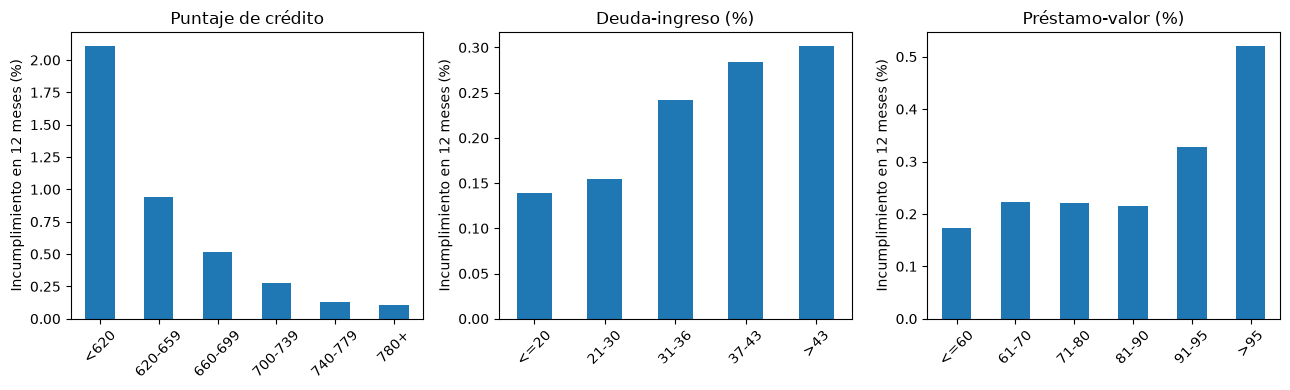

Tasa de incumplimiento en 12 meses: 0.244 % (680 de 279,060)


,variable,rango,creditos,tasa_pct
0,puntaje,<620,332,2.108
1,puntaje,620-659,12462,0.939
2,puntaje,660-699,34672,0.516
3,puntaje,700-739,63195,0.280
4,puntaje,740-779,87725,0.131
5,puntaje,780+,80524,0.104
0,deuda_ingreso,<=20,19384,0.139
1,deuda_ingreso,21-30,58392,0.154
2,deuda_ingreso,31-36,53281,0.242
3,deuda_ingreso,37-43,78599,0.284


In [13]:
p1 = consulta("SELECT e.y_p1, o.* FROM etiqueta_p1 e JOIN orig o USING (loan_id)")
TASA_P1 = p1.y_p1.mean()

p1["puntaje"] = pd.cut(p1.credit_score, [0, 619, 659, 699, 739, 779, 850], labels=["<620", "620-659", "660-699", "700-739", "740-779", "780+"])
p1["deuda_ingreso"] = pd.cut(p1.dti, [0, 20, 30, 36, 43, 100], labels=["<=20", "21-30", "31-36", "37-43", ">43"])
p1["prestamo_valor"] = pd.cut(p1.oltv, [0, 60, 70, 80, 90, 95, 1000], labels=["<=60", "61-70", "71-80", "81-90", "91-95", ">95"])

fig, axs = plt.subplots(1, 3, figsize=(13, 4))
tablas = []
for ax, (col, nombre) in zip(axs, [("puntaje", "Puntaje de crédito"), ("deuda_ingreso", "Deuda-ingreso (%)"),
                                   ("prestamo_valor", "Préstamo-valor (%)")]):
    t = p1.groupby(col, observed=True).y_p1.agg(creditos="size", tasa_pct="mean")
    t["tasa_pct"] = 100 * t.tasa_pct
    t.tasa_pct.plot.bar(ax=ax, rot=45)
    ax.set(title=nombre, xlabel="", ylabel="Incumplimiento en 12 meses (%)")
    tablas.append(t.reset_index().rename(columns={col: "rango"}).assign(variable=col))
fig.tight_layout()
guardar(fig, "incumplimiento_12m_por_perfil")
plt.show()

print(f"Tasa de incumplimiento en {VENTANA_P1} meses: {100 * TASA_P1:.3f} % ({p1.y_p1.sum():,} de {len(p1):,})")
pd.concat(tablas)[["variable", "rango", "creditos", "tasa_pct"]].round(3)

In [14]:
filas = []
for col in ["purpose", "occupancy", "channel", "first_time_homebuyer", "num_borrowers", "prop_type"]:
    t = p1.groupby(col).y_p1.agg(creditos="size", tasa="mean")
    for valor, r in t[t.creditos >= 1000].iterrows():
        filas.append({"variable": col, "valor": MAPAS.get(col, {}).get(valor, valor), "creditos": int(r.creditos),
                      "tasa_pct": round(100 * r.tasa, 3), "riesgo_relativo": round(r.tasa / TASA_P1, 2)})
pd.DataFrame(filas)

,variable,valor,creditos,tasa_pct,riesgo_relativo
0,purpose,Refinanciación con retiro,62977,0.281,1.15
1,purpose,Refinanciación sin retiro,39461,0.213,0.87
2,purpose,Compra,176622,0.237,0.97
3,occupancy,Inversión,23081,0.117,0.48
4,occupancy,Residencia principal,244028,0.260,1.07
5,occupancy,Segunda vivienda,11951,0.151,0.62
6,channel,Corredor,33962,0.236,0.97
7,channel,Corresponsal,93487,0.279,1.15
8,channel,Minorista,151611,0.224,0.92
9,first_time_homebuyer,No,204905,0.223,0.92


In [15]:
cruce = p1.pivot_table(index="puntaje", columns="prestamo_valor", values="y_p1", aggfunc="mean", observed=True)
conteo = p1.pivot_table(index="puntaje", columns="prestamo_valor", values="y_p1", aggfunc="size", observed=True)
print("Incumplimiento en 12 meses (%) por puntaje y préstamo-valor; vacío si la celda tiene menos de 200 créditos")
(100 * cruce.where(conteo >= 200)).round(2)

Incumplimiento en 12 meses (%) por puntaje y préstamo-valor; vacío si la celda tiene menos de 200 créditos


prestamo_valor,<=60,61-70,71-80,81-90,91-95,>95
puntaje,,,,,,
<620,NaN,NaN,NaN,NaN,NaN,NaN
620-659,0.60,0.70,1.07,1.22,1.36,3.02
660-699,0.32,0.46,0.48,0.56,0.77,0.78
700-739,0.19,0.19,0.26,0.20,0.39,0.54
740-779,0.07,0.11,0.12,0.16,0.16,0.26
780+,0.08,0.09,0.09,0.05,0.16,0.45


In [16]:
def auc(y, puntaje):
    m = pd.notna(y) & pd.notna(puntaje)
    y, r = np.asarray(y[m]), pd.Series(np.asarray(puntaje[m])).rank().to_numpy()
    n1 = y.sum(); n0 = len(y) - n1
    return (r[y == 1].sum() - n1 * (n1 + 1) / 2) / (n1 * n0)


# El AUC del puntaje es la línea base que el modelo de aprobación debe superar
candidatas = {
    "Puntaje de crédito": -p1.credit_score,
    "Tasa de interés original": p1.orig_rate,
    "Número de deudores": -p1.num_borrowers,
    "Préstamo-valor": p1.oltv,
    "Deuda-ingreso": p1.dti,
    "Porcentaje de seguro hipotecario": p1.mi_pct,
}
linea_base = pd.DataFrame([{"variable": k, "auc": round(auc(p1.y_p1, v), 4)} for k, v in candidatas.items()])
AUC_PUNTAJE = linea_base.auc.iloc[0]
linea_base.sort_values("auc", ascending=False)

,variable,auc
0,Puntaje de crédito,0.6999
1,Tasa de interés original,0.6466
2,Número de deudores,0.5911
3,Préstamo-valor,0.5730
4,Deuda-ingreso,0.5704
5,Porcentaje de seguro hipotecario,0.5496


In [17]:
positivos_pandemia = consulta(f"""
    SELECT COUNT(*) AS positivos,
           COUNT(*) FILTER (WHERE p.period BETWEEN {PANDEMIA[0]} AND {PANDEMIA[1]}) AS en_pandemia
    FROM etiqueta_p1 e JOIN resumen r USING (loan_id)
    JOIN perf p ON p.loan_id = r.loan_id AND p.mes = r.mes_primer_incumplimiento
    WHERE e.y_p1 = 1
""").iloc[0]
print(f"Positivos de la pregunta 1 con el incumplimiento dentro de la pandemia: "
      f"{int(positivos_pandemia.en_pandemia):,} de {int(positivos_pandemia.positivos):,}")

Positivos de la pregunta 1 con el incumplimiento dentro de la pandemia: 77 de 680


El puntaje de crédito es la variable que mejor ordena el riesgo por sí sola, y su AUC queda como línea base del modelo de aprobación. La deuda-ingreso y la relación préstamo-valor separan menos, pero dentro de un mismo rango de puntaje el préstamo-valor alto multiplica el incumplimiento, algo que una regla basada solo en el puntaje no ve. La tasa de interés original es la segunda variable. Un solo deudor y la primera vivienda también suben el riesgo. La pandemia casi no afecta esta etiqueta, porque la ventana de 12 meses de la cosecha termina al inicio de 2020.

## Curvas de incumplimiento y prepago por cosecha

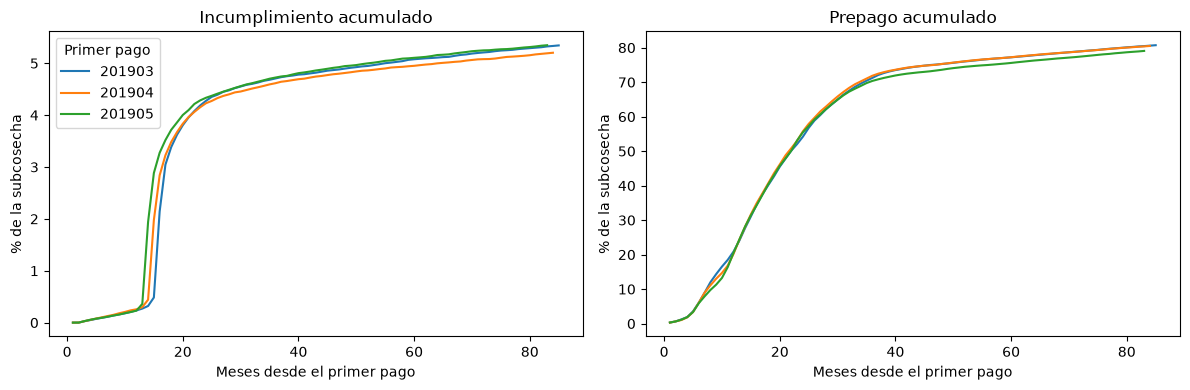

Primeros incumplimientos dentro de los primeros 12 meses: 4.6 %
Mediana de edad al primer incumplimiento: 16 meses


,cosecha,creditos,incumplimiento_12m,incumplimiento_24m,incumplimiento_final,prepago_12m,prepago_24m,prepago_final
0,201903,77623,0.24,4.27,5.34,20.87,54.21,80.72
1,201904,94070,0.26,4.23,5.20,20.22,55.76,80.51
2,201905,104489,0.23,4.33,5.35,20.50,55.48,79.07


In [18]:
cosechas = consulta("""
    SELECT o.first_payment_date AS cosecha, r.edad_primer_incumplimiento, r.codigo_salida, r.edad_salida, r.edad_maxima
    FROM resumen r JOIN orig o USING (loan_id) WHERE NOT r.defecto
""")
participacion = cosechas.cosecha.value_counts(normalize=True)
principales = sorted(participacion[participacion >= 0.01].index)
cosechas["edad_prepago"] = np.where(cosechas.codigo_salida == 1, cosechas.edad_salida, np.nan)


def acumulada(df, columna, edades):
    eventos = df[columna].dropna().to_numpy()
    return np.array([(eventos <= e).sum() for e in edades]) / len(df)


fig, axs = plt.subplots(1, 2, figsize=(12, 4))
resumen_cosechas = []
for c in principales:
    d = cosechas[cosechas.cosecha == c]
    edades = np.arange(1, int(d.edad_maxima.max()) + 1)
    inc, pre = acumulada(d, "edad_primer_incumplimiento", edades), acumulada(d, "edad_prepago", edades)
    axs[0].plot(edades, 100 * inc, label=str(c))
    axs[1].plot(edades, 100 * pre, label=str(c))
    resumen_cosechas.append({"cosecha": c, "creditos": len(d),
                             "incumplimiento_12m": 100 * inc[11], "incumplimiento_24m": 100 * inc[23], "incumplimiento_final": 100 * inc[-1],
                             "prepago_12m": 100 * pre[11], "prepago_24m": 100 * pre[23], "prepago_final": 100 * pre[-1]})
axs[0].set(title="Incumplimiento acumulado", xlabel="Meses desde el primer pago", ylabel="% de la subcosecha")
axs[1].set(title="Prepago acumulado", xlabel="Meses desde el primer pago", ylabel="% de la subcosecha")
axs[0].legend(title="Primer pago")
fig.tight_layout()
guardar(fig, "curvas_por_cosecha")
plt.show()

primeros = cosechas.edad_primer_incumplimiento.dropna()
print(f"Primeros incumplimientos dentro de los primeros {VENTANA_P1} meses: {100 * (primeros <= VENTANA_P1).mean():.1f} %")
print(f"Mediana de edad al primer incumplimiento: {primeros.median():.0f} meses")
pd.DataFrame(resumen_cosechas).round(2)

En esta cosecha el incumplimiento no lo marca la edad sino el calendario: es bajo durante el primer año y salta cuando la pandemia llega, alrededor del segundo año de vida, para luego crecer despacio. Las tres subcosechas se comportan igual, con un pequeño desfase en edad porque el choque llegó en la misma fecha a créditos de distinta edad. Para la pregunta 1, una ventana más larga que 12 meses quedaría dominada por los incumplimientos de la pandemia.

## Riesgo por estado

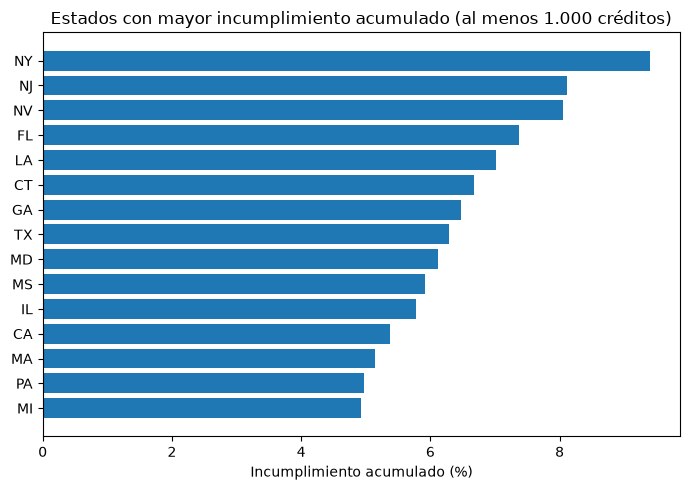

Estados con al menos 1.000 créditos: 40
Tasa acumulada: de 3.22 % a 9.39 % · tasa a 12 meses: de 0.00 % a 0.57 %
Correlación de rangos entre tasa acumulada y tasa a 12 meses: 0.32


,estado,creditos,tasa_acumulada_pct,tasa_12m_pct
0,NY,9496,9.39,0.25
1,NJ,6857,8.11,0.31
2,NV,3935,8.06,0.28
3,FL,20389,7.38,0.31
4,LA,2908,7.02,0.38
37,ID,2577,3.38,0.12
38,IA,1972,3.30,0.25
39,CO,8815,3.22,0.11


In [19]:
por_estado = consulta(f"""
    SELECT o.state AS estado, COUNT(*) AS creditos,
           100 * AVG((r.edad_primer_incumplimiento IS NOT NULL)::INTEGER) AS tasa_acumulada_pct,
           100 * AVG(COALESCE(r.edad_primer_incumplimiento <= {VENTANA_P1}, FALSE)::INTEGER) AS tasa_12m_pct
    FROM resumen r JOIN orig o USING (loan_id) WHERE NOT r.defecto
    GROUP BY 1 HAVING COUNT(*) >= 1000 ORDER BY 3 DESC
""")
top = por_estado.head(15).iloc[::-1]
fig, ax = plt.subplots(figsize=(7, 5))
ax.barh(top.estado, top.tasa_acumulada_pct)
ax.set(title="Estados con mayor incumplimiento acumulado (al menos 1.000 créditos)", xlabel="Incumplimiento acumulado (%)")
fig.tight_layout()
guardar(fig, "incumplimiento_por_estado")
plt.show()

print(f"Estados con al menos 1.000 créditos: {len(por_estado)}")
print(f"Tasa acumulada: de {por_estado.tasa_acumulada_pct.min():.2f} % a {por_estado.tasa_acumulada_pct.max():.2f} % · "
      f"tasa a 12 meses: de {por_estado.tasa_12m_pct.min():.2f} % a {por_estado.tasa_12m_pct.max():.2f} %")
print(f"Correlación de rangos entre tasa acumulada y tasa a 12 meses: "
      f"{por_estado.tasa_acumulada_pct.rank().corr(por_estado.tasa_12m_pct.rank()):.2f}")
pd.concat([por_estado.head(5), por_estado.tail(3)]).round(2)

El incumplimiento acumulado varía mucho entre estados y es más alto en el noreste, el sur y Nevada. La tasa a 12 meses, anterior a la pandemia, ordena los estados de otra forma, como muestra la correlación de rangos baja. La señal geográfica depende del periodo, y además puede funcionar como sustituto de características sensibles, así que su uso en el modelo de aprobación debe revisarse.

## Transiciones entre estados de mora

In [20]:
ORIGEN = ["Al día", "30 días", "60 días", "90+ días"]
DESTINO = ORIGEN + ["Prepago", "Otra salida"]
transiciones = consulta("""
    WITH t AS (
        SELECT dlq_num, dlq_status, zb, mes,
               LEAD(mes) OVER w AS mes_sig, LEAD(dlq_num) OVER w AS dlq_sig,
               LEAD(dlq_status) OVER w AS estado_sig, LEAD(zb) OVER w AS zb_sig
        FROM perf WHERE loan_id NOT IN (SELECT loan_id FROM resumen WHERE defecto)
        WINDOW w AS (PARTITION BY loan_id ORDER BY mes)
    )
    SELECT CASE WHEN dlq_status = 'RA' OR dlq_num >= 3 THEN '90+ días' WHEN dlq_num = 2 THEN '60 días'
                WHEN dlq_num = 1 THEN '30 días' WHEN dlq_num = 0 THEN 'Al día' END AS origen,
           CASE WHEN zb_sig = 1 THEN 'Prepago' WHEN zb_sig IS NOT NULL THEN 'Otra salida'
                WHEN estado_sig = 'RA' OR dlq_sig >= 3 THEN '90+ días' WHEN dlq_sig = 2 THEN '60 días'
                WHEN dlq_sig = 1 THEN '30 días' WHEN dlq_sig = 0 THEN 'Al día' END AS destino,
           COUNT(*) AS n
    FROM t WHERE zb IS NULL AND mes_sig = mes + 1
    GROUP BY 1, 2
""").dropna()
matriz_n = transiciones.pivot(index="origen", columns="destino", values="n").reindex(index=ORIGEN, columns=DESTINO).fillna(0)
matriz = 100 * matriz_n.div(matriz_n.sum(axis=1), axis=0)
print("Probabilidad (%) de pasar de cada estado (fila) a cada estado el mes siguiente (columna)")
matriz.round(1)

Probabilidad (%) de pasar de cada estado (fila) a cada estado el mes siguiente (columna)


destino,Al día,30 días,60 días,90+ días,Prepago,Otra salida
origen,,,,,,
Al día,96.9,0.7,0.0,0.0,2.4,0.0
30 días,38.8,33.2,25.8,0.1,2.0,0.0
60 días,15.3,9.0,23.0,51.3,1.3,0.0
90+ días,9.9,0.8,1.0,86.6,1.3,0.3


Un crédito al día casi nunca cae en mora de un mes a otro, pero una vez atrasado el riesgo escala rápido: desde 60 días la mitad llega a 90 o más, y a partir de 90 días el estado es muy persistente. Lo que más anticipa la mora grave es el estado de los meses recientes, lo que respalda usar la secuencia mensual en la pregunta 2.

## Mora e indulgencia en el tiempo

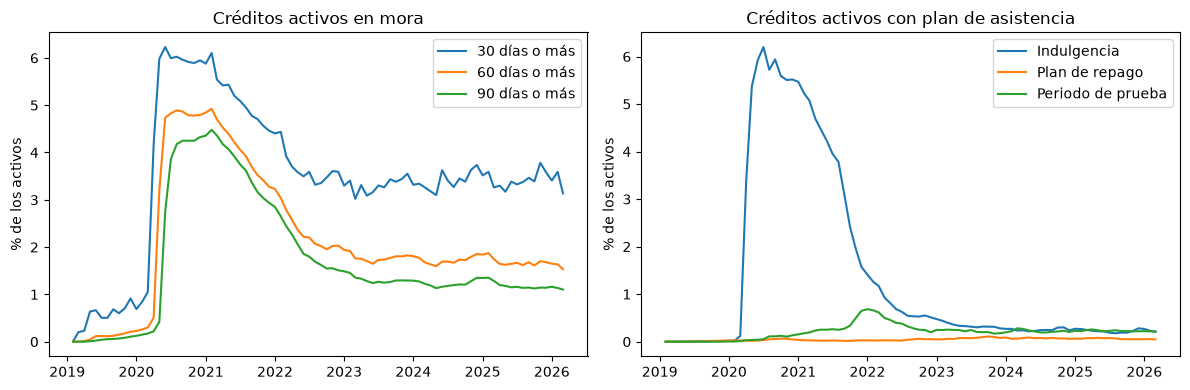

,serie,promedio_antes_pandemia,maximo,mes_del_maximo,promedio_desde_2023
0,mora_30,0.55,6.23,202006,3.38
1,mora_90,0.05,4.48,202102,1.24
2,indulgencia,0.01,6.20,202007,0.27
3,mora_por_desastre,0.00,6.40,202007,0.37


In [21]:
tiempo = consulta("""
    SELECT period,
           100 * AVG(COALESCE(dlq_num >= 1 OR dlq_status = 'RA', FALSE)::INTEGER) AS mora_30,
           100 * AVG(COALESCE(dlq_num >= 2 OR dlq_status = 'RA', FALSE)::INTEGER) AS mora_60,
           100 * AVG(COALESCE(dlq_num >= 3 OR dlq_status = 'RA', FALSE)::INTEGER) AS mora_90,
           100 * AVG(COALESCE(assistance_plan = 'F', FALSE)::INTEGER) AS indulgencia,
           100 * AVG(COALESCE(assistance_plan = 'R', FALSE)::INTEGER) AS plan_repago,
           100 * AVG(COALESCE(assistance_plan = 'T', FALSE)::INTEGER) AS periodo_prueba,
           100 * AVG(COALESCE(dlq_disaster = 'Y', FALSE)::INTEGER) AS mora_por_desastre,
           COUNT(*) AS activos
    FROM perf WHERE zb IS NULL GROUP BY 1 ORDER BY 1
""")
tiempo = tiempo[tiempo.activos >= 0.05 * tiempo.activos.max()]
tiempo["fecha"] = a_fecha(tiempo.period)

fig, axs = plt.subplots(1, 2, figsize=(12, 4))
for col, nombre in [("mora_30", "30 días o más"), ("mora_60", "60 días o más"), ("mora_90", "90 días o más")]:
    axs[0].plot(tiempo.fecha, tiempo[col], label=nombre)
for col, nombre in [("indulgencia", "Indulgencia"), ("plan_repago", "Plan de repago"), ("periodo_prueba", "Periodo de prueba")]:
    axs[1].plot(tiempo.fecha, tiempo[col], label=nombre)
axs[0].set(title="Créditos activos en mora", ylabel="% de los activos")
axs[1].set(title="Créditos activos con plan de asistencia", ylabel="% de los activos")
for ax in axs:
    ax.legend()
fig.tight_layout()
guardar(fig, "mora_y_asistencia")
plt.show()

antes = tiempo[tiempo.period < PANDEMIA[0]]
despues = tiempo[tiempo.period >= 202301]
filas = []
for col in ["mora_30", "mora_90", "indulgencia", "mora_por_desastre"]:
    filas.append({"serie": col, "promedio_antes_pandemia": antes[col].mean(),
                  "maximo": tiempo[col].max(), "mes_del_maximo": int(tiempo.loc[tiempo[col].idxmax(), "period"]),
                  "promedio_desde_2023": despues[col].mean()})
pd.DataFrame(filas).round(2)

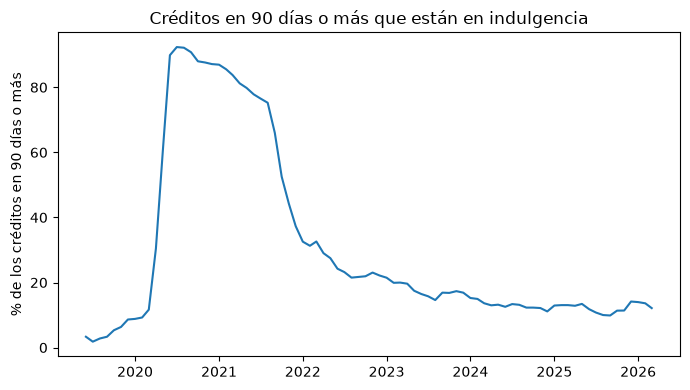

Máximo: 92.4 % en 202007 (6,550 de 7,091 créditos)
Promedio desde 2023: 14.2 %


Primeros incumplimientos por estado de mora: 14,804, de los cuales 82.8 % ocurrieron en la pandemia


,pct_en_indulgencia,pct_volvio_al_dia
en_pandemia,,
Fuera de la pandemia,24.6,73.6
Pandemia,91.2,88.3


In [22]:
# El estado de mora se mide contra los pagos contractuales, así que la indulgencia acumula meses de atraso
mora_grave = consulta("""
    SELECT period,
           COUNT(*) FILTER (WHERE dlq_num >= 3 OR dlq_status = 'RA') AS en_90,
           COUNT(*) FILTER (WHERE (dlq_num >= 3 OR dlq_status = 'RA') AND assistance_plan = 'F') AS en_90_indulgencia
    FROM perf WHERE zb IS NULL GROUP BY 1 ORDER BY 1
""")
mora_grave = mora_grave[mora_grave.period.isin(tiempo.period) & (mora_grave.en_90 >= 30)]
mora_grave["pct_indulgencia"] = 100 * mora_grave.en_90_indulgencia / mora_grave.en_90

fig, ax = plt.subplots(figsize=(7, 4))
ax.plot(a_fecha(mora_grave.period), mora_grave.pct_indulgencia)
ax.set(title="Créditos en 90 días o más que están en indulgencia", ylabel="% de los créditos en 90 días o más")
fig.tight_layout()
guardar(fig, "indulgencia_en_mora_grave")
plt.show()

pico = mora_grave.loc[mora_grave.pct_indulgencia.idxmax()]
print(f"Máximo: {pico.pct_indulgencia:.1f} % en {int(pico.period)} ({int(pico.en_90_indulgencia):,} de {int(pico.en_90):,} créditos)")
print(f"Promedio desde 2023: {mora_grave.loc[mora_grave.period >= 202301, 'pct_indulgencia'].mean():.1f} %")

primeros_inc = consulta(f"""
    SELECT r.loan_id, p.period BETWEEN {PANDEMIA[0]} AND {PANDEMIA[1]} AS en_pandemia,
           COALESCE(p.assistance_plan = 'F', FALSE) AS en_indulgencia,
           EXISTS (SELECT 1 FROM perf q WHERE q.loan_id = r.loan_id AND q.mes > r.mes_primer_incumplimiento
                   AND q.dlq_num = 0 AND q.zb IS NULL) AS se_curo
    FROM resumen r JOIN perf p ON p.loan_id = r.loan_id AND p.mes = r.mes_primer_incumplimiento
    WHERE NOT r.defecto AND p.zb IS NULL
""")
print(f"Primeros incumplimientos por estado de mora: {len(primeros_inc):,}, "
      f"de los cuales {100 * primeros_inc.en_pandemia.mean():.1f} % ocurrieron en la pandemia")
tabla = primeros_inc.groupby("en_pandemia")[["en_indulgencia", "se_curo"]].mean().mul(100).round(1)
tabla.index = tabla.index.map({True: "Pandemia", False: "Fuera de la pandemia"})
tabla.rename(columns={"en_indulgencia": "pct_en_indulgencia", "se_curo": "pct_volvio_al_dia"})

La pandemia domina la serie: la mora de todos los niveles salta en 2020 y regresa después a niveles más bajos que el pico, pero por encima de los previos. El salto coincide con la indulgencia y con la mora atribuida a desastres. Durante la pandemia casi toda la mora grave era indulgencia, y la mayoría de esos créditos volvió a estar al día. Con la definición actual, esos créditos cuentan como incumplimientos aunque tenían permiso para no pagar. Un modelo desplegado debe vigilar la indulgencia y la mora por desastre, porque un aumento de ambas cambia la relación entre atraso e incumplimiento.

## Pregunta 2: alerta temprana de mora

In [23]:
TASA_P2 = consulta("SELECT AVG(y_p2) FROM etiqueta_p2").iloc[0, 0]
origen_90 = consulta(f"""
    WITH primero AS (
        SELECT loan_id, MIN(mes) AS mes_90 FROM perf
        WHERE (dlq_num >= 3 OR dlq_status = 'RA') AND loan_id NOT IN (SELECT loan_id FROM resumen WHERE defecto)
        GROUP BY 1
    )
    SELECT CASE WHEN p.dlq_num = 0 THEN 'Al día' WHEN p.dlq_num = 1 THEN '30 días' WHEN p.dlq_num = 2 THEN '60 días'
                ELSE 'Sin registro' END AS estado_3_meses_antes,
           COUNT(*) AS creditos
    FROM primero f LEFT JOIN perf p ON p.loan_id = f.loan_id AND p.mes = f.mes_90 - {VENTANA_P2}
    GROUP BY 1 ORDER BY 2 DESC
""")
origen_90["pct"] = (100 * origen_90.creditos / origen_90.creditos.sum()).round(1)
print(f"Tasa de la etiqueta: {100 * TASA_P2:.4f} % de los créditos-mes al día")
print("Estado 3 meses antes de llegar por primera vez a 90 días:")
origen_90

Tasa de la etiqueta: 0.1636 % de los créditos-mes al día
Estado 3 meses antes de llegar por primera vez a 90 días:


,estado_3_meses_antes,creditos,pct
0,Al día,11913,80.5
1,30 días,2220,15.0
2,60 días,664,4.5
3,Sin registro,8,0.1


In [24]:
senales = consulta("""
    WITH b AS (
        SELECT e.y_p2,
               CASE WHEN COALESCE(e.atrasos_12m_previos, 0) = 0 THEN '0' WHEN e.atrasos_12m_previos = 1 THEN '1'
                    WHEN e.atrasos_12m_previos <= 3 THEN '2-3' ELSE '4+' END AS atrasos_12m,
               CASE WHEN o.credit_score < 620 THEN '<620' WHEN o.credit_score < 660 THEN '620-659'
                    WHEN o.credit_score < 700 THEN '660-699' WHEN o.credit_score < 740 THEN '700-739'
                    WHEN o.credit_score < 780 THEN '740-779' WHEN o.credit_score IS NOT NULL THEN '780+' END AS puntaje,
               CASE WHEN e.eltv <= 60 THEN '<=60' WHEN e.eltv <= 70 THEN '61-70' WHEN e.eltv <= 80 THEN '71-80'
                    WHEN e.eltv <= 90 THEN '81-90' WHEN e.eltv IS NOT NULL THEN '>90' END AS prestamo_valor_actual
        FROM etiqueta_p2 e JOIN orig o USING (loan_id)
    )
    SELECT 'atrasos_12m' AS variable, atrasos_12m AS rango, COUNT(*) AS creditos_mes, 100 * AVG(y_p2) AS tasa_pct FROM b GROUP BY 1, 2
    UNION ALL SELECT 'puntaje', puntaje, COUNT(*), 100 * AVG(y_p2) FROM b WHERE puntaje IS NOT NULL GROUP BY 1, 2
    UNION ALL SELECT 'prestamo_valor_actual', prestamo_valor_actual, COUNT(*), 100 * AVG(y_p2) FROM b WHERE prestamo_valor_actual IS NOT NULL GROUP BY 1, 2
    ORDER BY 1, 2
""")
senales["riesgo_relativo"] = senales.tasa_pct / (100 * TASA_P2)
senales.round(3)

,variable,rango,creditos_mes,tasa_pct,riesgo_relativo
0,atrasos_12m,0,8704916,0.123,0.753
1,atrasos_12m,1,190545,0.490,2.993
2,atrasos_12m,2-3,103924,0.905,5.534
3,atrasos_12m,4+,130469,1.795,10.971
4,prestamo_valor_actual,61-70,1213296,0.221,1.349
5,prestamo_valor_actual,71-80,1452148,0.229,1.400
6,prestamo_valor_actual,81-90,894418,0.329,2.014
7,prestamo_valor_actual,<=60,4176508,0.097,0.592
8,prestamo_valor_actual,>90,428837,0.149,0.909
9,puntaje,620-659,485098,0.380,2.321


In [25]:
def tasa_variante(estados_origen, umbral, ventana=VENTANA_P2):
    return consulta(f"""
        WITH base AS (
            SELECT p.loan_id, p.mes, p.dlq_num, p.zb, r.mes_ultimo, r.codigo_salida,
                   (COALESCE(p.dlq_num >= {umbral}, FALSE) OR p.dlq_status = 'RA'
                    OR COALESCE(p.zb IN {esquema.CODIGOS_CIERRE_INCUMPLIMIENTO}, FALSE))::INTEGER AS evento
            FROM perf p JOIN resumen r USING (loan_id) WHERE NOT r.defecto
        ),
        v AS (SELECT *, MAX(evento) OVER (PARTITION BY loan_id ORDER BY mes RANGE BETWEEN 1 FOLLOWING AND {ventana} FOLLOWING) AS despues FROM base)
        SELECT COUNT(*) AS creditos_mes, SUM(COALESCE(despues, 0))::BIGINT AS positivos, 100 * AVG(COALESCE(despues, 0)) AS tasa_pct
        FROM v
        WHERE dlq_num IN ({", ".join(map(str, estados_origen))}) AND zb IS NULL
          AND (despues = 1 OR mes + {ventana} <= mes_ultimo OR codigo_salida IS NOT NULL)
    """).iloc[0]


pd.DataFrame([tasa_variante([0], 3).rename("Al día a 90+ días (carta)"),
              tasa_variante([0, 1], 3).rename("Al día o 30 días a 90+ días"),
              tasa_variante([0], 2).rename("Al día a 60+ días")]).astype({"creditos_mes": int, "positivos": int}).round(4)

,creditos_mes,positivos,tasa_pct
Al día a 90+ días (carta),9129854,14938,0.1636
Al día o 30 días a 90+ días,9236499,35421,0.3835
Al día a 60+ días,9129930,42799,0.4688


In [26]:
p2_anual = consulta("""
    SELECT period // 100 AS anio, COUNT(*) AS creditos_mes, SUM(y_p2)::BIGINT AS positivos, 100 * AVG(y_p2) AS tasa_pct
    FROM etiqueta_p2 GROUP BY 1 ORDER BY 1
""")
p2_pandemia = consulta(f"""
    SELECT 100 * AVG(y_p2) FILTER (WHERE period BETWEEN {PANDEMIA[0]} AND {PANDEMIA[1]}) AS dentro,
           100 * AVG(y_p2) FILTER (WHERE period NOT BETWEEN {PANDEMIA[0]} AND {PANDEMIA[1]}) AS fuera,
           100 * SUM(y_p2) FILTER (WHERE period BETWEEN {PANDEMIA[0]} AND {PANDEMIA[1]}) / SUM(y_p2) AS pct_positivos_en_pandemia
    FROM etiqueta_p2
""").iloc[0]
print(f"Tasa en la pandemia: {p2_pandemia.dentro:.4f} % · fuera: {p2_pandemia.fuera:.4f} % · "
      f"positivos en la pandemia: {p2_pandemia.pct_positivos_en_pandemia:.1f} %")
p2_anual.round(4)

Tasa en la pandemia: 0.3811 % · fuera: 0.0587 % · positivos en la pandemia: 75.8 %


,anio,creditos_mes,positivos,tasa_pct
0,2019,2579906,522,0.0202
1,2020,2188995,10198,0.4659
2,2021,1249374,1485,0.1189
3,2022,891184,881,0.0989
4,2023,800954,697,0.0870
5,2024,738274,620,0.0840
6,2025,680137,530,0.0779
7,2026,1030,5,0.4854


La definición de la carta captura la mayor parte de las llegadas a 90 días. Las dos variantes multiplican entre dos y tres veces los positivos disponibles para entrenar. El historial reciente de atrasos es la señal más fuerte; el puntaje al originarse ordena el riesgo desde 620 y el préstamo-valor actual no es monótono. La mayoría de los positivos está en la pandemia, así que un modelo entrenado con esta cosecha aprendería sobre todo ese episodio. La tasa de 2026 no es comparable: en los últimos meses solo se pueden etiquetar los créditos que incumplieron o salieron.

## Conclusiones

In [27]:
pd.Series({
    "Créditos": f"{n_creditos:,}",
    "Desempeño hasta": PERIODO_FIN,
    "Activos al final": f"{100 * activos_final / n_creditos:.1f} %",
    "Incumplimiento en 12 meses (pregunta 1)": f"{100 * TASA_P1:.3f} %",
    "AUC del puntaje (línea base)": f"{AUC_PUNTAJE:.3f}",
    "Llegada a 90 días en 3 meses (pregunta 2)": f"{100 * TASA_P2:.4f} %",
    "Positivos de la pregunta 2 en la pandemia": f"{p2_pandemia.pct_positivos_en_pandemia:.1f} %",
}, name="valor").to_frame()

,valor
Créditos,"279,861"
Desempeño hasta,202603
Activos al final,19.8 %
Incumplimiento en 12 meses (pregunta 1),0.244 %
AUC del puntaje (línea base),0.700
Llegada a 90 días en 3 meses (pregunta 2),0.1636 %
Positivos de la pregunta 2 en la pandemia,75.8 %


- Los datos están listos para la canalización con reglas simples: tratar los códigos de no disponible como nulos, descartar las columnas sin información, calcular la edad desde el primer pago, excluir los créditos con código 96 y revisar los valores extremos de préstamo-valor y plazo.
- Pregunta 1: el incumplimiento temprano es raro y lo ordena sobre todo el puntaje, cuyo AUC es la línea base. La deuda-ingreso, el número de deudores y la primera vivienda agregan información, y el préstamo-valor alto multiplica el riesgo dentro de cada rango de puntaje.
- Pregunta 2: el historial reciente de atrasos es la mejor señal, lo que respalda el enfoque secuencial. La mayoría de los positivos viene de la pandemia, y el equipo debe decidir si excluye ese periodo, lo marca o usa el plan de asistencia como variable.
- La indulgencia cambió la relación entre atraso e incumplimiento en pocos meses. El tablero debe mostrarla junto con la mora y el monitoreo del modelo debe vigilarla.
- Es un solo trimestre, distorsionado por la pandemia y por la ola de prepagos. Las conclusiones deben contrastarse con las demás cosechas de entrenamiento.